In [1]:
import qgtoolbox as qg
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import xwavelet.wavelet as xwl
import xrft

from tqdm import tqdm
from matplotlib.colors import LogNorm, Normalize
from scipy.ndimage import gaussian_filter
from scipy.signal import find_peaks
from IPython.display import clear_output

dm = qg.DataManager(root_dir='..')
print(dm.root)

/home/slava/Work/climate/wavelet-jet-analysis


In [2]:
EXP = 'huge-jet-atm'
N_EPOCH = 100
METHOD = 'test'

sim_path = dm.make_dir(path=dm.raw, name=EXP)
res_path = dm.make_dir(path=dm.processed, name=EXP)
stat_path = dm.make_dir(path=res_path, name=METHOD)

cfg_path = dm.config / f"{EXP}.yaml"
ds_sim_path = sim_path / f"{EXP}.nc"
ds_stat_path = stat_path / f"{EXP}.nc"

ds_sim_path_e = qg.epoch_path(ds_sim_path, N_EPOCH)
ds_stat_path_e = qg.epoch_path(ds_stat_path, N_EPOCH)

In [4]:
def calc_spectra(ds, gamma=None, n_scale=None):
    x, y = ds.x, ds.y  
    n_grid = ds.attrs['grid.n_grid']
    x0 = ds.x.values[1] - ds.x.values[0]
    if n_scale is None:
        n_scale = n_grid
    s_vals = np.geomspace(2.0, n_grid, n_scale)
    s = xr.DataArray(s_vals, dims=["s"], coords={"s": s_vals})
    Wax = xwl.cwt2(ds.ux, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Way = xwl.cwt2(ds.uy, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Ea = np.abs(Wax)**2 / Wax["s"] * x0**2 + np.abs(Way)**2 / Way["s"] * x0**2
    return Ea

def calc_sfourier_spectra(ds, gamma=None, n_scale=None):
    x, y = ds.x, ds.y  
    n_grid = ds.attrs['grid.n_grid']
    x0 = ds.x.values[1] - ds.x.values[0]
    if n_scale is None:
        n_scale = n_grid
    # s_vals = np.geomspace(2.0, n_grid, n_scale)
    n = np.arange(1, n_grid // 2 + 1)
    s_vals = (n_grid / n)[::-1]
    s = xr.DataArray(s_vals, dims=["s"], coords={"s": s_vals})
    Fax = xwl.cft2(ds.ux, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='sfourier', center=False)
    Fay = xwl.cft2(ds.uy, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='sfourier', center=False)
    Ea = np.abs(Fax)**2 / Fax["s"] + np.abs(Fay)**2 / Fay["s"]
    return Ea

def calc_fourier_spectra(ds, gamma=None, n_scale=None):
    x, y = ds.x, ds.y  
    n_grid = ds.attrs['grid.n_grid']
    x0 = ds.x.values[1] - ds.x.values[0]
    if n_scale is None:
        n_scale = n_grid
    # s_vals = np.geomspace(2.0, n_grid, n_scale)
    n = np.arange(1, n_grid // 2 + 1)
    s_vals = (n_grid / n)[::-1]
    s = xr.DataArray(s_vals, dims=["s"], coords={"s": s_vals})
    Fax = xwl.cft2(ds.ux, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='fourier', center=True)
    Fay = xwl.cft2(ds.uy, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='fourier', center=True)
    Ea = np.abs(Fax)**2 / Fax["s"] + np.abs(Fay)**2 / Fay["s"]
    return Ea

def grad(v):
    vh = xrft.fft(v, dim=['y', 'x'])
    lag_y = vh.freq_y.attrs.get('direct_lag', 0.0)
    lag_x = vh.freq_x.attrs.get('direct_lag', 0.0)
    k_x, k_y = 2 * np.pi * vh.freq_x, 2 * np.pi * vh.freq_y
    grad_vxh = 1j * vh * k_x
    grad_vyh = 1j * vh * k_y 
    grad_vx = xrft.ifft(grad_vxh, dim=['freq_y', 'freq_x'], lag=[lag_y, lag_x]).real
    grad_vy = xrft.ifft(grad_vyh, dim=['freq_y', 'freq_x'], lag=[lag_y, lag_x]).real
    return grad_vx, grad_vy

def transfer(ux, uy):
    gradx_ux, grady_ux = grad(ux)
    gradx_uy, grady_uy = grad(uy)
    t_ux = ux * gradx_ux.values +  uy * grady_ux.values
    t_uy = ux * gradx_uy.values +  uy * grady_uy.values
    return t_ux, t_uy

def calc_fourier_flux(ds, gamma=None, n_scale=None):
    x, y = ds.x, ds.y  
    n_grid = ds.attrs['grid.n_grid']
    x0 = ds.x.values[1] - ds.x.values[0]
    if n_scale is None:
        n_scale = n_grid
    # s_vals = np.geomspace(2.0, n_grid, n_scale)
    n = np.arange(1, n_grid // 2 + 1)
    s_vals = (n_grid / n)[::-1]
    s = xr.DataArray(s_vals, dims=["s"], coords={"s": s_vals})
    tx, ty = transfer(ds.ux, ds.uy)

    Waux = xwl.cft2(ds.ux, s, dim=['y', 'x'], x0=x0, ntheta=4, wtype='fourier', center=True)
    Wauy = xwl.cft2(ds.uy, s, dim=['y', 'x'], x0=x0, ntheta=4, wtype='fourier', center=True)
    
    Watx = xwl.cft2(tx, s, dim=['y', 'x'], x0=x0, ntheta=4, wtype='fourier', center=True)
    Waty = xwl.cft2(ty, s, dim=['y', 'x'], x0=x0, ntheta=4, wtype='fourier', center=True)

    ea = - np.real(np.conj(Waux) * Watx + np.conj(Wauy) * Waty ) / Waux["s"] * x0**2
    return ea


def plot_spec(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.Eam.values))
    Eaz = ds.Eaz.isel(time=t_idx)
    Eam = ds.Eam.isel(time=t_idx)
    loglog = axis.loglog(k, Eam/EEa, color='black', label='avg (M)', linestyle='-')
    loglog = axis.loglog(k, Eaz/EEa, color='black', label='avg (Z)', linestyle='--')
    axis.set_title(f'Energy Fourier Spectrum $\\tilde E$ | $\\tilde E_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_ylabel('E(k)')
    axis.set_ylim(1e-8, 1e1)
    axis.grid(True)
    axis.legend()
    return loglog

def plot_wspec(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.Eam.values))
    Eaz = ds.Eaz.isel(time=t_idx)
    Eam = ds.Eam.isel(time=t_idx)
    loglog = axis.loglog(k, Eaz/EEa, color=qg.RED, label='zonal (kx)')
    loglog = axis.loglog(k, Eam/EEa, color=qg.BLUE, label='meridional (ky)')
    axis.set_title(f'Energy Wavelet Spectrum $\\tilde E$ | $\\tilde E_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_ylabel('E(k)')
    axis.set_ylim(1e-8, 1e1)
    axis.grid(True)
    axis.legend()
    return loglog

def plot_wspec_jet(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.Eam_aj.values))
    Eaz_j = ds.Eaz_j.isel(time=t_idx)
    Eam_j = ds.Eam_j.isel(time=t_idx)
    Eaz_aj = ds.Eaz_aj.isel(time=t_idx)
    Eam_aj = ds.Eam_aj.isel(time=t_idx)
    loglog = axis.loglog(k, Eam_j/EEa, color=qg.RED, label='jet (M)', linestyle='-')
    loglog = axis.loglog(k, Eaz_j/EEa, color=qg.RED, label='jet (Z)', linestyle='--')
    loglog = axis.loglog(k, Eam_aj/EEa, color=qg.BLUE, label='anti-jet (M)', linestyle='-')
    loglog = axis.loglog(k, Eaz_aj/EEa, color=qg.BLUE, label='anti-jet (Z)', linestyle='--')
    axis.set_title(f'Energy Wavelet Spectrum $\\tilde E$ | $\\tilde E_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_ylabel('E(k)')
    axis.set_ylim(1e-8, 1e1)
    axis.grid(True)
    axis.legend()
    return loglog

def plot_transfer(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.eam.values))
    eaz = ds.eaz.isel(time=t_idx)
    eam = ds.eam.isel(time=t_idx)
    loglog = axis.plot(k, eam/EEa, color='black', label='avg (M)', linestyle='-')
    loglog = axis.plot(k, eaz/EEa, color='black', label='avg (Z)', linestyle='--')
    axis.set_title(f'Energy Fourier Transfer $\\hat \\varepsilon$ | $\\hat \\varepsilon_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_xscale('log')
    axis.set_ylabel('$\\varepsilon$ (k)')
    axis.set_ylim(-1.1, +1.1)
    axis.grid(True)
    axis.legend()
    return loglog

def plot_flux(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.eam.cumsum(dim='s').values))
    eaz = (ds.eaz.cumsum(dim='s')).isel(time=t_idx)
    eam = (ds.eam.cumsum(dim='s')).isel(time=t_idx)
    loglog = axis.plot(k, eam/EEa, color='black', label='avg (M)', linestyle='-')
    loglog = axis.plot(k, eaz/EEa, color='black', label='avg (Z)', linestyle='--')
    axis.set_title(f'Energy Fourier Flux $\\hat \\varepsilon$ | $\\hat \\varepsilon_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_xscale('log')
    axis.set_ylabel('$\\varepsilon$ (k)')
    axis.set_ylim(-1.1, +1.1)
    axis.grid(True)
    axis.legend()
    return loglog


In [14]:
ds = qg.load_simulation(ds_sim_path, n_epoch=10, k_epoch=91)
ds = qg.calc_statistics(ds)
ds = qg.calc_fourier(ds)
# qg.save_dataset(data=ds, path=ds_stat_path)

# ds = qg.load_dataset(ds_sim_path_e)
# ds = qg.calc_statistics(ds)
# ds = qg.calc_fourier(ds)
# qg.save_dataset(data=ds, path=ds_stat_path_e)

In [15]:
ds

<xarray.Dataset> Size: 6GB
Dimensions:  (time: 1000, y: 256, x: 256, kx: 256, ky: 256, k: 45)
Coordinates:
  * time     (time) float64 8kB 9.001e+03 9.002e+03 ... 9.999e+03 1e+04
  * y        (y) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * x        (x) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * kx       (kx) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * ky       (ky) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * k        (k) float64 360B 1.874 4.4 7.16 9.981 ... 117.4 120.2 123.0 125.9
    lev      int64 8B 1
Data variables: (12/14)
    q        (time, y, x) float64 524MB -0.2409 -0.3504 ... -0.6038 -0.5918
    ux       (time, y, x) float64 524MB 0.02535 0.02794 ... 0.0956 0.0992
    uy       (time, y, x) float64 524MB -0.01363 -0.01718 ... 0.02769 0.02382
    p        (time, y, x) float64 524MB -0.008248 -0.008622 ... -0.008434
    v        (time, y, x) float64 524MB 0.02878 0.0328 0.03846 ... 0.09953 0.102
    qp       (time, y, x) float64 524MB -0.1795 -0.289 -0.3044 ... 30.75 30.76
    ...       ...
    eh       (time, ky, kx) float64 524MB 2.603e-35 2.419e-35 ... 3.002e-35
    ehx      (time, y, kx) float64 524MB 1.118e-37 1.896e-35 ... 1.832e-35
    ehy      (time, ky, x) float64 524MB 4.312e-36 6.441e-37 ... 2.326e-37
    Ehr      (time, k) float64 360kB 1.463 4.775 0.4077 ... 8.191e-28 2.394e-32
    Ehx      (time, kx) float64 2MB 3.816e-35 7.906e-35 ... 9.384e-36 9.907e-35
    Ehy      (time, ky) float64 2MB 1.205e-35 1.648e-35 ... 3.072e-35 3.673e-35
Attributes: (12/13)
    title:                   Huge Anisotropic 2D Turbulence
    source:                  pyqg.BTModel
    architecture.n_threads:  1
    grid.n_grid:             256
    model.rek:               0.0001
    model.cnu:               0.2
    ...                      ...
    model.kf:                32.0
    model.dkf:               2.0
    model.beta:              5.0
    simulation.dt:           0.01
    simulation.t_write:      1.0
    simulation.t_epoch:      100.0

2.2 2.1475731030398975
3.2 3.399301425954581


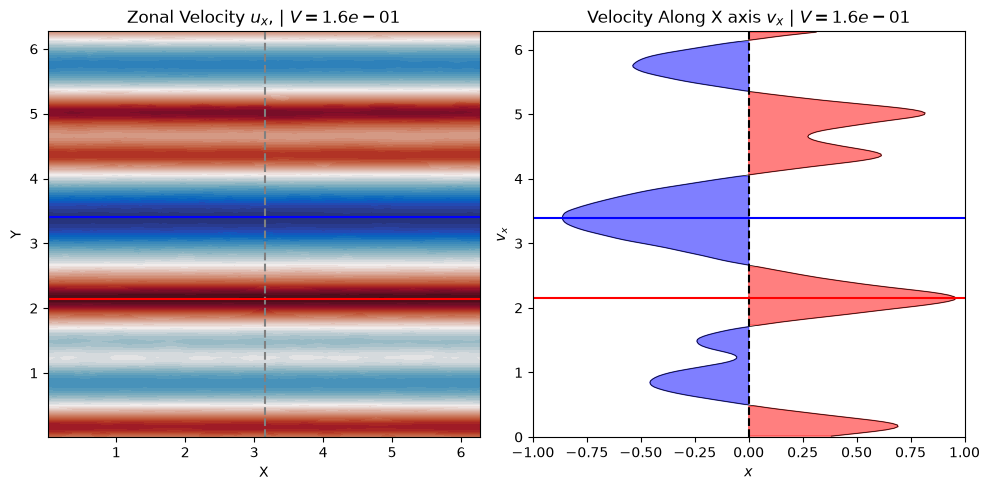

In [16]:
x0 = 128
y_j = 2.2
y_aj = 3.2
n_jets = 3
n_grid = ds.attrs['grid.n_grid']
n_times = len(ds.time)
x = ds.x.values
y = ds.y.values
V = np.abs(ds.ux).max().values

ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)

Jet_Idx, AJet_Idx = [], []

vx = ds_m.ux.isel(time=-1, x=x0).values / V
vx_periodic = np.concatenate([vx, vx])
peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
peaks_idx = peaks_idx[peaks_idx < n_grid]
top = peaks_idx[np.argsort(vx[peaks_idx])[::-1][:n_jets]]
if len(top) < n_jets:
    top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
jet_idx = np.sort(top)
j_idx = jet_idx[np.argmin(np.abs(y[jet_idx] - y_j))]

print(y_j, y[j_idx])
y_j = y[j_idx]

vx = ds_m.ux.isel(time=-1, x=x0).values / V
avx = -vx
vx_periodic = np.concatenate([avx, avx])
peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
peaks_idx = peaks_idx[peaks_idx < n_grid]
top = peaks_idx[np.argsort(avx[peaks_idx])[::-1][:n_jets]]
if len(top) < n_jets:
    top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
ajet_idx = np.sort(top)
aj_idx = ajet_idx[np.argmin(np.abs(y[ajet_idx] - y_aj))]
print(y_aj, y[aj_idx])
y_aj = y[aj_idx]

for time in range(len(ds.time)):
    vx = ds.ux.isel(time=time, x=x0).values / V
    vx_periodic = np.concatenate([vx, vx])
    peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
    peaks_idx = peaks_idx[peaks_idx < n_grid]
    top = peaks_idx[np.argsort(vx[peaks_idx])[::-1][:n_jets]]
    if len(top) < n_jets:
        top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
    jet_idx = np.sort(top)
    j_idx = jet_idx[np.argmin(np.abs(y[jet_idx] - y_j))]
    Jet_Idx.append(j_idx)

for time in range(len(ds.time)):
    vx = ds.ux.isel(time=time, x=x0).values / V
    avx = -vx
    vx_periodic = np.concatenate([avx, avx])
    peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
    peaks_idx = peaks_idx[peaks_idx < n_grid]
    top = peaks_idx[np.argsort(avx[peaks_idx])[::-1][:n_jets]]
    if len(top) < n_jets:
        top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
    ajet_idx = np.sort(top)
    aj_idx = ajet_idx[np.argmin(np.abs(y[ajet_idx] - y_aj))]
    AJet_Idx.append(aj_idx)


fig, axis = plt.subplots(ncols=2, nrows=1, figsize=(10,5))
vel_z = qg.plot_zonal_velocity(ds_m, axis[0], t_idx=-1, x0=x0)
vel_y = qg.plot_y_velocity(ds_m, axis[1], t_idx=-1, x0=x0)
# spec = plot_wspec_jet(ds_m, axis[2], t_idx=-1)

axis[0].axhline(y_j, color='red', linestyle='-')
axis[1].axhline(y_j, color='red', linestyle='-')


axis[0].axhline(y_aj, color='blue', linestyle='-')
axis[1].axhline(y_aj, color='blue', linestyle='-')

fig.tight_layout()
# fig.savefig(stat_path / 'avg-spec.png', dpi=1000) 
plt.show()
plt.close()

# FFT Grid Points

In [17]:
eaz_Jet, eam_Jet = [], []
n_scale = 100
for time in tqdm(range(len(ds.time))):
    ea_jet = calc_fourier_flux(ds.isel(time=time), gamma=(0, 0), n_scale=n_scale)
    eaz_jet = ea_jet.sel(angle=0.0, method='nearest')
    eam_jet = ea_jet.sel(angle=np.pi/2, method='nearest')
    eaz_Jet.append(eaz_jet)
    eam_Jet.append(eam_jet)

eaz_jet = xr.concat(eaz_Jet, dim='time', data_vars='all')
eam_jet = xr.concat(eam_Jet, dim='time', data_vars='all')

ds['eaz'] = eaz_jet
ds['eam'] = eam_jet

100%|██████████| 1000/1000 [39:17<00:00,  2.36s/it]


In [19]:
qg.save_dataset(data=ds, path=ds_stat_path)
# ds = qg.load_dataset(ds_stat_path)
ds

<xarray.Dataset> Size: 6GB
Dimensions:  (time: 1000, y: 256, x: 256, kx: 256, ky: 256, k: 45, s: 128)
Coordinates:
  * time     (time) float64 8kB 9.001e+03 9.002e+03 ... 9.999e+03 1e+04
  * y        (y) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * x        (x) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * kx       (kx) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * ky       (ky) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * k        (k) float64 360B 1.874 4.4 7.16 9.981 ... 117.4 120.2 123.0 125.9
  * s        (s) float64 1kB 0.04909 0.04947 0.04987 ... 2.094 3.142 6.283
    lev      int64 8B 1
    angle    float64 8B 0.0
Data variables: (12/16)
    q        (time, y, x) float64 524MB -0.2409 -0.3504 ... -0.6038 -0.5918
    ux       (time, y, x) float64 524MB 0.02535 0.02794 ... 0.0956 0.0992
    uy       (time, y, x) float64 524MB -0.01363 -0.01718 ... 0.02769 0.02382
    p        (time, y, x) float64 524MB -0.008248 -0.008622 ... -0.008434
    v        (time, y, x) float64 524MB 0.02878 0.0328 0.03846 ... 0.09953 0.102
    qp       (time, y, x) float64 524MB -0.1795 -0.289 -0.3044 ... 30.75 30.76
    ...       ...
    ehy      (time, ky, x) float64 524MB 4.312e-36 6.441e-37 ... 2.326e-37
    Ehr      (time, k) float64 360kB 1.463 4.775 0.4077 ... 8.191e-28 2.394e-32
    Ehx      (time, kx) float64 2MB 3.816e-35 7.906e-35 ... 9.384e-36 9.907e-35
    Ehy      (time, ky) float64 2MB 1.205e-35 1.648e-35 ... 3.072e-35 3.673e-35
    eaz      (time, s) float64 1MB 2.93e-25 1.494e-23 ... -6.457e-09 -4.399e-10
    eam      (time, s) float64 1MB -5.838e-25 2.806e-22 ... 2.2e-08 -1.539e-07
Attributes: (12/13)
    title:                   Huge Anisotropic 2D Turbulence
    source:                  pyqg.BTModel
    architecture.n_threads:  1
    grid.n_grid:             256
    model.rek:               0.0001
    model.cnu:               0.2
    ...                      ...
    model.kf:                32.0
    model.dkf:               2.0
    model.beta:              5.0
    simulation.dt:           0.01
    simulation.t_write:      1.0
    simulation.t_epoch:      100.0

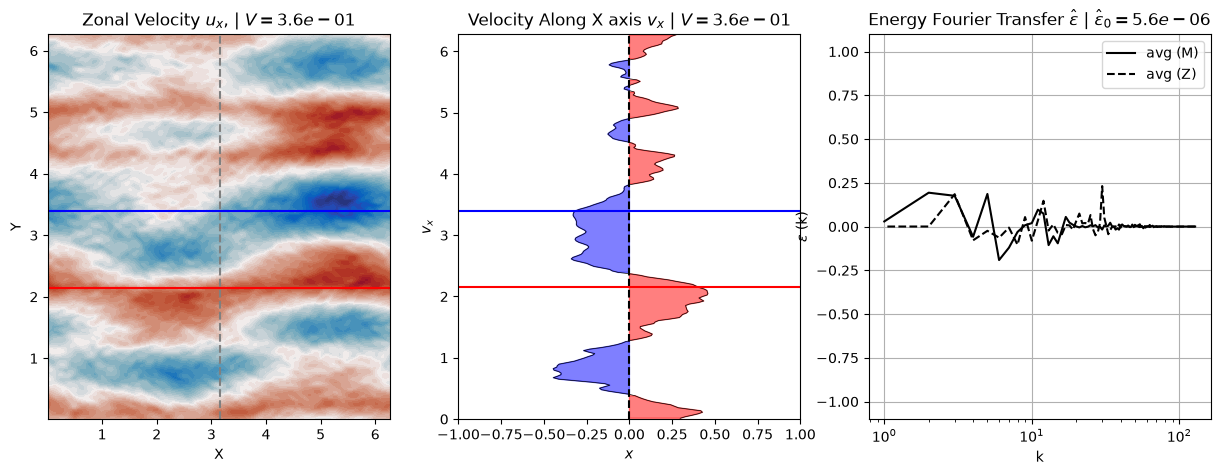

In [20]:
for time in range(10):
    clear_output(wait=True)
    fig, axis = plt.subplots(ncols=3, nrows=1, figsize=(15,5))
    vel_z = qg.plot_zonal_velocity(ds, axis[0], t_idx=time, x0=x0)
    vel_y = qg.plot_y_velocity(ds, axis[1], t_idx=time, x0=x0)
    spec = plot_transfer(ds, axis[2], t_idx=time)

    # jet_idx = Jet_Idx[time]
    axis[0].axhline(y_j, color='red', linestyle='-')
    axis[1].axhline(y_j, color='red', linestyle='-')

    # ajet_idx = AJet_Idx[time]
    axis[0].axhline(y_aj, color='blue', linestyle='-')
    axis[1].axhline(y_aj, color='blue', linestyle='-')

    plt.show()
    plt.close()

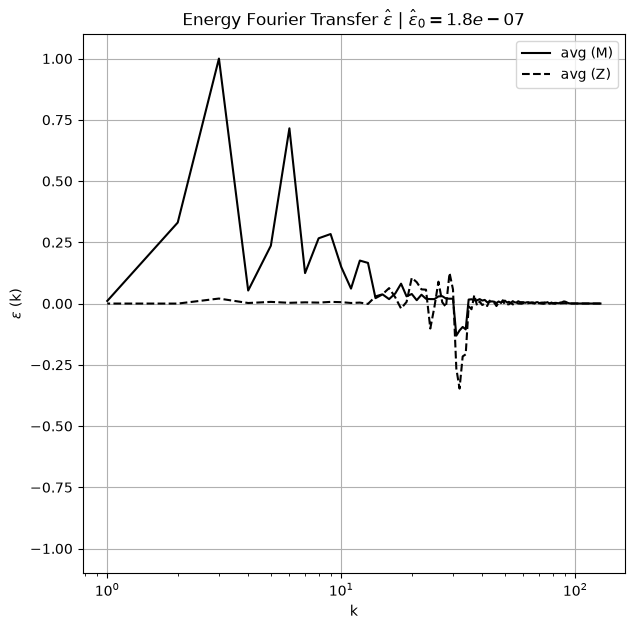

In [21]:
ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)
fig, axis = plt.subplots(figsize=(7, 7))
plot_transfer(ds_m, axis, t_idx=-1)
# fig.savefig(stat_path / 'wspec.png', dpi=1000)

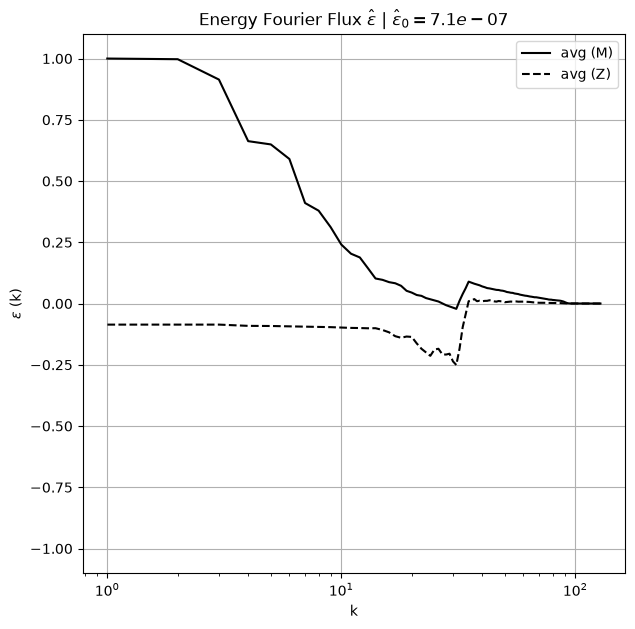

In [22]:
ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)
fig, axis = plt.subplots(figsize=(7, 7))
plot_flux(ds_m, axis, t_idx=-1)
# fig.savefig(stat_path / 'wspec.png', dpi=1000)

In [8]:
# qg.save_dataset(data=ds, path=ds_stat_path)
# ds = qg.load_dataset(ds_stat_path)
ds

<xarray.Dataset> Size: 577MB
Dimensions:  (time: 100, y: 256, x: 256, kx: 256, ky: 256, k: 45, s: 128)
Coordinates:
  * time     (time) float64 800B 9.901e+03 9.902e+03 ... 9.999e+03 1e+04
  * y        (y) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * x        (x) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * kx       (kx) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * ky       (ky) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * k        (k) float64 360B 1.874 4.4 7.16 9.981 ... 117.4 120.2 123.0 125.9
  * s        (s) float64 1kB 0.04909 0.04947 0.04987 ... 2.094 3.142 6.283
    lev      int64 8B 1
    angle    float64 8B 0.0
Data variables: (12/16)
    q        (time, y, x) float64 52MB -0.8546 -0.6639 ... -0.6038 -0.5918
    ux       (time, y, x) float64 52MB 0.04114 0.03695 0.03512 ... 0.0956 0.0992
    uy       (time, y, x) float64 52MB -0.0589 -0.05951 ... 0.02769 0.02382
    p        (time, y, x) float64 52MB 0.02546 0.024 ... -0.009064 -0.008434
    v        (time, y, x) float64 52MB 0.07184 0.07005 0.06825 ... 0.09953 0.102
    qp       (time, y, x) float64 52MB -0.7933 -0.6026 -0.4501 ... 30.75 30.76
    ...       ...
    ehy      (time, ky, x) float64 52MB 6.441e-37 6.745e-36 ... 2.326e-37
    Ehr      (time, k) float64 36kB 1.616 4.79 0.3851 ... 8.191e-28 2.394e-32
    Ehx      (time, kx) float64 205kB 3.337e-35 6.511e-35 ... 9.907e-35
    Ehy      (time, ky) float64 205kB 2.209e-35 2.119e-35 ... 3.673e-35
    eaz      (time, s) float64 102kB 1.176e-24 1.493e-24 ... -4.399e-10
    eam      (time, s) float64 102kB 3.671e-24 4.029e-22 ... 2.2e-08 -1.539e-07
Attributes: (12/13)
    title:                   Huge Anisotropic 2D Turbulence
    source:                  pyqg.BTModel
    architecture.n_threads:  1
    grid.n_grid:             256
    model.rek:               0.0001
    model.cnu:               0.2
    ...                      ...
    model.kf:                32.0
    model.dkf:               2.0
    model.beta:              5.0
    simulation.dt:           0.01
    simulation.t_write:      1.0
    simulation.t_epoch:      100.0

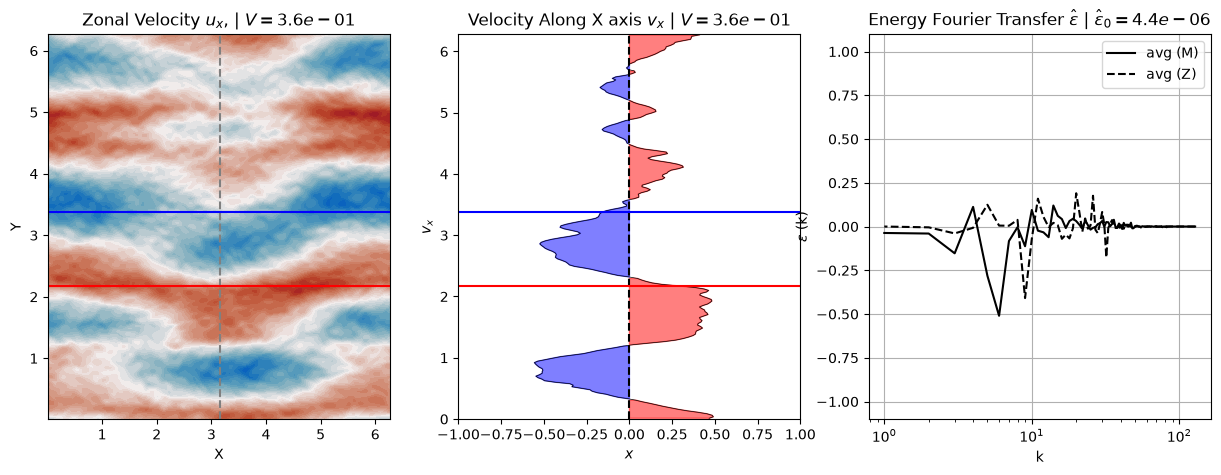

In [11]:
for time in range(10):
    clear_output(wait=True)
    fig, axis = plt.subplots(ncols=3, nrows=1, figsize=(15,5))
    vel_z = qg.plot_zonal_velocity(ds, axis[0], t_idx=time, x0=x0)
    vel_y = qg.plot_y_velocity(ds, axis[1], t_idx=time, x0=x0)
    spec = plot_transfer(ds, axis[2], t_idx=time)

    # jet_idx = Jet_Idx[time]
    axis[0].axhline(y_j, color='red', linestyle='-')
    axis[1].axhline(y_j, color='red', linestyle='-')

    # ajet_idx = AJet_Idx[time]
    axis[0].axhline(y_aj, color='blue', linestyle='-')
    axis[1].axhline(y_aj, color='blue', linestyle='-')

    plt.show()
    plt.close()

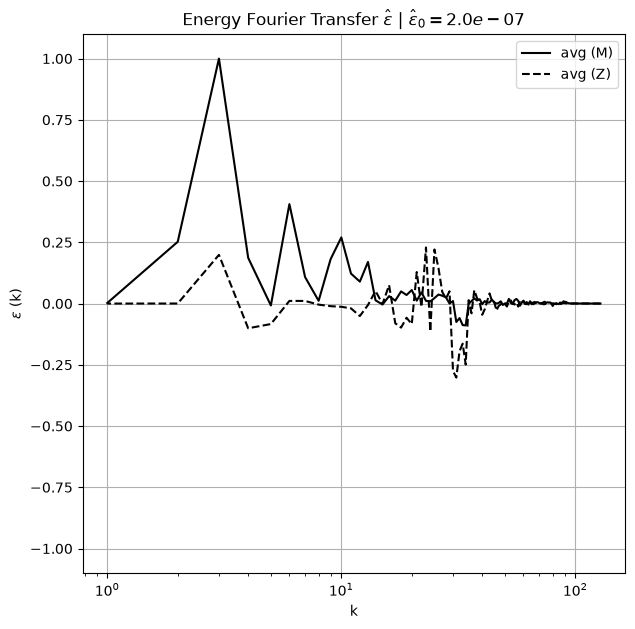

In [12]:
ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)
fig, axis = plt.subplots(figsize=(7, 7))
plot_transfer(ds_m, axis, t_idx=-1)
# fig.savefig(stat_path / 'wspec.png', dpi=1000)

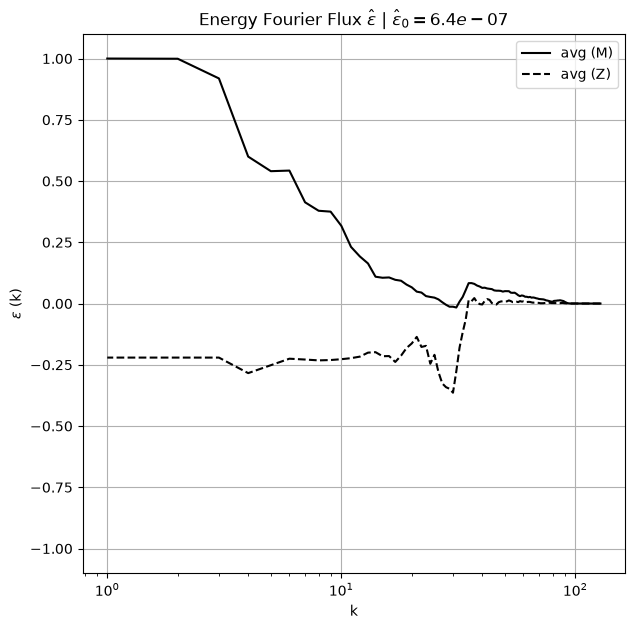

In [13]:
ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)
fig, axis = plt.subplots(figsize=(7, 7))
plot_flux(ds_m, axis, t_idx=-1)
# fig.savefig(stat_path / 'wspec.png', dpi=1000)